# Calentamiento antes de descongelar

Dos de las nueve arquitecturas colapsaban al azar cuando el ajuste fino empezaba contra una cabeza aleatoria: `descongelarCola` deja las `BatchNormalization` en las estadísticas de ImageNet mientras las convoluciones ya se mueven. Aquí se mide si basta con calentar, con la receta real de los nueve notebooks —misma tasa y mismos pesos de clase en ambas fases—, de modo que la única variable sea la fase congelada. Se prueba sobre las dos que colapsaban más MobileNetV3Small de control.

In [1]:
# En Kaggle clona el repo; en local no hace nada.
import os
import subprocess
import sys
from pathlib import Path

REPO = "https://github.com/CCSandoval/ButterflyModeling.git"

if Path("/kaggle").exists():
    CLON = "/tmp/ButterflyModeling"
    if not Path(CLON).exists():                     # el repo es público: clonar no pide credenciales
        subprocess.run(["git", "clone", "--depth", "1", REPO, CLON], check=True)
    sys.path.insert(0, CLON)
    os.chdir(CLON)
    print("clon en", CLON, "·", subprocess.run(
        ["git", "log", "-1", "--format=%h %s"], cwd=CLON,
        capture_output=True, text=True).stdout.strip())

    try:
        from kaggle_secrets import UserSecretsClient

        os.environ["GITHUB_TOKEN"] = UserSecretsClient().get_secret("GITHUB_TOKEN")
    except Exception:
        print("sin GITHUB_TOKEN: no se publicará")

Cloning into '/tmp/ButterflyModeling'...


clon en /tmp/ButterflyModeling · d3d6948 Update Grad-CAM output images with selected improved distilled model


In [2]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "corpus.json").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print("Raíz del proyecto:", ROOT)

Raíz del proyecto: /tmp/ButterflyModeling


In [3]:
import numpy as np
import pandas as pd
import tensorflow as tf

from scripts import corpus
from scripts import modelRegistry as registro
from scripts.architectures import IMG_SIZE, buildModel, descongelarCola, preprocessFn
from scripts.dataPipeline import aumentadorFotometrico, loadSplit, preparar
from scripts.vizStyle import SERIE_1, SERIE_2, applyStyle

ARQUITECTURAS = ("mobilenet_v2", "resnet50_v2", "mobilenet_v3_small")

LOTE = 32
EPOCAS_CALENTAMIENTO = 5
EPOCAS_AJUSTE = 8
TASA = 1e-4              # la misma de los nueve notebooks, en las dos fases
SEMILLA = 42

FIGURAS = registro.OUTPUTS_DIR / "figuras"
FIGURAS.mkdir(exist_ok=True)

tf.keras.utils.set_random_seed(SEMILLA)
corpus.materializar()

dsTrainCrudo, clases = loadSplit("dataset/train", IMG_SIZE, LOTE)
dsValCrudo, _ = loadSplit("dataset/validate", IMG_SIZE, LOTE, shuffle=False)
pesosClase = corpus.classWeights()
NUM_CLASES = len(clases)
AZAR = 1.0 / NUM_CLASES
print(f"{NUM_CLASES} clases · azar {AZAR:.4f} · {IMG_SIZE[0]}x{IMG_SIZE[1]}")

Found 17716 files belonging to 100 classes.


I0000 00:00:1792693986.765547      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792693986.769180      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 2533 files belonging to 100 classes.
100 clases · azar 0.0100 · 448x448


## 1 · Con y sin calentamiento

`calentar=False` reproduce la configuración que colapsaba.

In [4]:
def entrenarEnDosFases(arquitectura, calentar):
    tf.keras.utils.set_random_seed(SEMILLA)
    preprocess = preprocessFn(arquitectura)
    modelo = buildModel(arquitectura, NUM_CLASES, aumentar=True)
    dsT = preparar(dsTrainCrudo, preprocess, aumentadorFotometrico())
    dsV = preparar(dsValCrudo, preprocess)
    historia = {}

    if calentar:
        modelo.compile(optimizer=tf.keras.optimizers.Adam(TASA),
                       loss="categorical_crossentropy", metrics=["accuracy"])
        historia = modelo.fit(dsT, validation_data=dsV, epochs=EPOCAS_CALENTAMIENTO,
                              class_weight=pesosClase, verbose=0).history

    descongelarCola(modelo, 0.30)
    modelo.compile(optimizer=tf.keras.optimizers.Adam(TASA),
                   loss="categorical_crossentropy", metrics=["accuracy"])
    ajuste = modelo.fit(dsT, validation_data=dsV, epochs=EPOCAS_AJUSTE,
                        class_weight=pesosClase, verbose=0).history

    del modelo
    tf.keras.backend.clear_session()
    return {k: historia.get(k, []) + v for k, v in ajuste.items()}


curvas, fases = {}, []
for arquitectura in ARQUITECTURAS:
    for calentar in (False, True):
        h = entrenarEnDosFases(arquitectura, calentar)
        curvas[f"{arquitectura}|{int(calentar)}"] = h
        fases.append({
            "arquitectura": arquitectura,
            "calentamiento": calentar,
            "train_acc": h["accuracy"][-1],
            "val_acc": h["val_accuracy"][-1],
            "val_loss_max": max(h["val_loss"]),
            "colapsa": h["accuracy"][-1] < 5 * AZAR,
        })
        print(f"{arquitectura:20s} calentamiento={str(calentar):5s} "
              f"train={h['accuracy'][-1]:.4f} val={h['val_accuracy'][-1]:.4f} "
              f"pico_val_loss={max(h['val_loss']):9.2f}")

resultados = pd.DataFrame(fases)
registro.writeJson(registro.OUTPUTS_DIR / "calentamiento.json", {
    "num_clases": NUM_CLASES,
    "azar": round(AZAR, 4),
    "epocas_calentamiento": EPOCAS_CALENTAMIENTO,
    "epocas_ajuste": EPOCAS_AJUSTE,
    "tasa": TASA,
    "resultados": resultados.to_dict("records"),
    "curvas": curvas,
})

resultados

/tmp/ButterflyModeling/scripts/architectures.py:48: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = baseClass(weights="imagenet", include_top=False, input_tensor=tensor)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
mobilenet_v2         calentamiento=False train=0.0108 val=0.0111 pico_val_loss=   323.85
mobilenet_v2         calentamiento=True  train=0.7610 val=0.7122 pico_val_loss=     4.21
94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
resnet50_v2          calentamiento=False train=0.0320 val=0.0189 pico_val_loss=     8.26
resnet50_v2          calentamiento=True  train=0.8710 val=0.8452 pico_val_loss=     3.88


/usr/local/lib/python3.13/dist-packages/keras/src/applications/mobilenet_v3.py:454: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(


4334752/4334752 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
mobilenet_v3_small   calentamiento=False train=0.6053 val=0.7280 pico_val_loss=     3.51
mobilenet_v3_small   calentamiento=True  train=0.7157 val=0.8105 pico_val_loss=     3.81


,arquitectura,calentamiento,train_acc,val_acc,val_loss_max,colapsa
0,mobilenet_v2,False,0.010781,0.011054,323.851318,True
1,mobilenet_v2,True,0.761007,0.712199,4.207650,False
2,resnet50_v2,False,0.032005,0.018950,8.264709,True
3,resnet50_v2,True,0.871021,0.845243,3.876428,False
4,mobilenet_v3_small,False,0.605272,0.727991,3.506054,False
5,mobilenet_v3_small,True,0.715681,0.810501,3.808227,False


## 2 · Las curvas

El valor de la última época no distingue «aprendió despacio» de «nunca despegó».

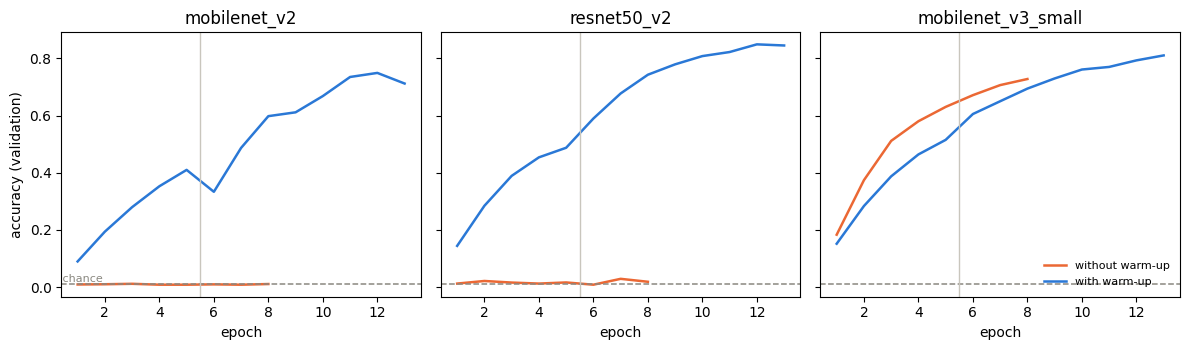

In [5]:
import matplotlib.pyplot as plt

fig, ejes = plt.subplots(1, len(ARQUITECTURAS), figsize=(4 * len(ARQUITECTURAS), 3.6),
                         sharey=True)
for eje, arquitectura in zip(ejes, ARQUITECTURAS):
    for calentar, color in ((False, SERIE_2), (True, SERIE_1)):
        serie = curvas[f"{arquitectura}|{int(calentar)}"]["val_accuracy"]
        eje.plot(range(1, len(serie) + 1), serie, color=color, linewidth=1.8,
                 label="with warm-up" if calentar else "without warm-up")
    eje.axhline(AZAR, color="#8a8880", linestyle="--", linewidth=1.1)
    eje.axvline(EPOCAS_CALENTAMIENTO + 0.5, color="#c9c6bd", linewidth=1)
    eje.set(title=arquitectura, xlabel="epoch")
ejes[0].set_ylabel("accuracy (validation)")
ejes[0].text(0.3, AZAR, " chance", fontsize=8, va="bottom", color="#8a8880")
ejes[-1].legend(loc="lower right", frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIGURAS / "calentamiento.png", dpi=300, bbox_inches="tight")
plt.show()

## 3 · Veredicto

In [6]:
for arquitectura in ARQUITECTURAS:
    sub = resultados[resultados.arquitectura == arquitectura].set_index("calentamiento")
    sin, con = sub.loc[False], sub.loc[True]
    veredicto = ("rescatada" if sin["colapsa"] and not con["colapsa"]
                 else "colapsa igual" if sin["colapsa"]
                 else "ya funcionaba")
    print(f"{arquitectura:20s} sin {sin['val_acc']:.3f} -> con {con['val_acc']:.3f} "
          f"({con['val_acc'] - sin['val_acc']:+.3f})  {veredicto}")


from scripts.kaggle import publicarArchivos
if Path("/kaggle").exists() and os.environ.get("GITHUB_TOKEN"):
    publicarArchivos("Add warm-up diagnostic",
                     "outputs/calentamiento.json",
                     "outputs/figuras/calentamiento.png")

mobilenet_v2         sin 0.011 -> con 0.712 (+0.701)  rescatada
resnet50_v2          sin 0.019 -> con 0.845 (+0.826)  rescatada
mobilenet_v3_small   sin 0.728 -> con 0.811 (+0.083)  ya funcionaba
Add warm-up diagnostic
